# Notebook 3 : un vrai trade sur le Brent

On met ensemble les notebooks 1 (la couverture) et 2 (l'estimation de σ) sur les vrais prix du Brent. Chaque 1er janvier de 2013 à 2024, la banque vend un call d'un an à la monnaie ($K = S_0$), le price avec Black-Scholes ($r = 3\,\%$) et le σ estimé sur l'année d'avant, puis le couvre chaque jour avec ce même σ. C'est `hedge_one_path`, avec la vraie année de prix à la place d'un chemin simulé.

## 0. Remarque : Black-Scholes contre Black-76

On traite le Brent comme une action achetée avec de l'argent emprunté. En réalité `BZ=F` est un future, et le modèle adapté est Black-76 (pas de $r$ dans $d_1$). Sur le trade de 2023, l'écart de prime est de 12 % ; les P&L, eux, changent de moins de 0,3 \$ par trade. On gardera Black-76 pour le modèle final.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from spread_options.analytics import bs_call, bs_delta
from spread_options.data import get_prices
from spread_options.hedging import hedge_one_path
from spread_options.products import call_payoff
from spread_options.volatility import historical_vol, ewma_vol

prices = get_prices("BZ=F", "01/01/2012", "31/12/2024")
T, r = 1.0, 0.03 # one-year option; Brent modelled like a stock, rate 3% (see the Black-76 remark)
years = list(range(2013, 2025))

In [2]:
# 2023 trade: Brent at 82.1 $, at-the-money call, sigma = 37% (EWMA at 31/12/2022)
F, K_ex, sigma_ex = 82.1, 82.1, 0.37
bs_stock = bs_call(F, K_ex, T, r, sigma_ex) # our model: Black-Scholes, Brent treated as a stock
black76 = np.exp(-r * T) * bs_call(F, K_ex, T, 0.0, sigma_ex) # Black-76 = e^{-rT} x the formula with r = 0
print(f"Black-Scholes (notre modèle) {bs_stock:.2f} $ | Black-76 (option sur future) {black76:.2f} $ "
      f"| écart {bs_stock - black76:.2f} $ ({bs_stock / black76 - 1:.0%})")

Black-Scholes (notre modèle) 13.12 $ | Black-76 (option sur future) 11.69 $ | écart 1.43 $ (12%)


## 1. D'où vient le P&L : quatre années fictives

Avec $r = 0$, le P&L se résume à : prime + gains des barils − payoff = prime − coût réel de la couverture. La prime est un budget ; la question est de savoir si la couverture a coûté plus ou moins. Exemple : call de strike 100 pricé à 20 %, couvert une fois par trimestre.

In [3]:
K_ex, sigma_ex = 100.0, 0.2 # toy call: strike 100, priced with sigma = 20%
r_toy = 0.0 # toy examples: no interest, so that only the purchases and sales of barrels matter
premium = bs_call(100.0, K_ex, T, r_toy, sigma_ex) # cash received on January 1st
toy_paths = {"calme, finit dans la monnaie": [100, 103, 101, 104, 105],
             "calme, finit hors de la monnaie": [100, 98, 99, 97, 96],
             "agitée, finit hors de la monnaie": [100, 112, 95, 108, 96],
             "agitée, finit dans la monnaie": [100, 88, 105, 92, 108]}
for name, toy in toy_paths.items():
    toy = np.array(toy, dtype=float)
    n = len(toy) - 1 # 4 rebalancings, one per quarter
    dt = T / n
    held = 0.0 # barrels held before today's trade
    gain_total = 0.0 # sum of what the barrels earned (+) or lost (-)
    print(f"--- année {name} : vol réalisée {historical_vol(toy, days_per_year=4):.0%}, prime reçue {premium:.2f} $")
    for i in range(n):
        delta = bs_delta(toy[i], K_ex, T - i * dt, r_toy, sigma_ex) # barrels to hold until the next date
        gain = delta * (toy[i + 1] - toy[i]) # what the barrels earn (or lose) until the next date
        gain_total += gain
        print(f"   S = {toy[i]:5.1f} | delta {delta:.3f} | {'achète' if delta > held else 'vend'} {abs(delta - held):.3f} "
              f"| S passe à {toy[i + 1]:5.1f} : gain des barils {gain:+6.2f} $")
        held = delta
    payoff = call_payoff(toy[-1], K_ex)
    total = premium + gain_total - payoff
    check = hedge_one_path(toy, T, r_toy, premium, lambda S, tl: bs_delta(S, K_ex, tl, r_toy, sigma_ex),
                           lambda ST: call_payoff(ST, K_ex))
    print(f"   coût réel {payoff - gain_total:5.2f} $ | P&L = {premium:.2f} {gain_total:+.2f} - {payoff:.2f} = {total:+.2f} $ "
          f"(hedge_one_path : {check:+.2f} $)")

--- année calme, finit dans la monnaie : vol réalisée 5%, prime reçue 7.97 $
   S = 100.0 | delta 0.540 | achète 0.540 | S passe à 103.0 : gain des barils  +1.62 $
   S = 103.0 | delta 0.602 | achète 0.062 | S passe à 101.0 : gain des barils  -1.20 $
   S = 101.0 | delta 0.556 | vend 0.045 | S passe à 104.0 : gain des barils  +1.67 $
   S = 104.0 | delta 0.671 | achète 0.115 | S passe à 105.0 : gain des barils  +0.67 $
   coût réel  2.24 $ | P&L = 7.97 +2.76 - 5.00 = +5.72 $ (hedge_one_path : +5.72 $)
--- année calme, finit hors de la monnaie : vol réalisée 3%, prime reçue 7.97 $
   S = 100.0 | delta 0.540 | achète 0.540 | S passe à  98.0 : gain des barils  -1.08 $
   S =  98.0 | delta 0.488 | vend 0.052 | S passe à  99.0 : gain des barils  +0.49 $
   S =  99.0 | delta 0.500 | achète 0.012 | S passe à  97.0 : gain des barils  -1.00 $
   S =  97.0 | delta 0.400 | vend 0.100 | S passe à  96.0 : gain des barils  -0.40 $
   coût réel  1.99 $ | P&L = 7.97 -1.99 - 0.00 = +5.97 $ (hedge_one_p

Le signe du P&L ne dépend pas de la fin du call (dans ou hors de la monnaie), mais de la vol réalisée comparée aux 20 % du budget : les années calmes (3 à 5 %) gagnent environ 6 \$, les années agitées (31 à 34 %) perdent 3 à 7 \$.

## 2. P&L réel : vol historique contre EWMA

Même trade chaque année, une fois avec chaque estimateur. Seul σ change.

In [4]:
pnl = {"histo": [], "ewma": []} # one P&L per year for each estimator
for year in years:
    path = prices[str(year)].to_numpy() # every daily price of the year: the real scenario
    S0 = path[0]
    K = S0 # at-the-money: strike = price on the first day
    payoff_fn = lambda ST: call_payoff(ST, K)
    sigmas = {"histo": historical_vol(prices[str(year - 1)]), # both known on January 1st
              "ewma": ewma_vol(prices[str(year - 1)])}
    line = f"{year} | S0 {S0:5.1f} -> ST {path[-1]:5.1f}"
    for name, sigma in sigmas.items():
        price0 = bs_call(S0, K, T, r, sigma) # premium paid by the client
        delta_fn = lambda S, time_left: bs_delta(S, K, time_left, r, sigma) # hedge with the same sigma
        result = hedge_one_path(path, T, r, price0, delta_fn, payoff_fn)
        pnl[name].append(result)
        line += f" | {name} σ {sigma:4.0%} prime {price0:5.2f} P&L {result:+6.2f}"
    print(line)

pnl = {name: np.array(values) for name, values in pnl.items()} # lists -> arrays
print()
for name, values in pnl.items():
    print(f"{name:5s} : P&L moyen {values.mean():+.2f} $ | P&L absolu moyen {np.abs(values).mean():.2f} $")

2013 | S0 112.5 -> ST 110.8 | histo σ  23% prime 11.99 P&L  +4.98 | ewma σ  18% prime  9.73 P&L  +1.57
2014 | S0 107.8 -> ST  57.3 | histo σ  17% prime  8.80 P&L  +1.04 | ewma σ  14% prime  7.81 P&L  +0.22
2015 | S0  56.4 -> ST  37.3 | histo σ  21% prime  5.46 P&L  -7.27 | ewma σ  37% prime  9.04 P&L  -1.92
2016 | S0  37.2 -> ST  56.1 | histo σ  44% prime  6.97 P&L  -0.13 | ewma σ  40% prime  6.32 P&L  -0.84
2017 | S0  55.5 -> ST  66.6 | histo σ  45% prime 10.58 P&L  +5.14 | ewma σ  35% prime  8.48 P&L  +2.83
2018 | S0  66.6 -> ST  53.8 | histo σ  24% prime  7.29 P&L  -2.04 | ewma σ  20% prime  6.36 P&L  -3.05
2019 | S0  54.9 -> ST  66.0 | histo σ  31% prime  7.43 P&L  -0.51 | ewma σ  56% prime 12.85 P&L  +6.18
2020 | S0  66.2 -> ST  51.8 | histo σ  31% prime  9.15 P&L  -1.24 | ewma σ  24% prime  7.28 P&L  -1.16


2021 | S0  51.1 -> ST  77.8 | histo σ  71% prime 14.80 P&L  +6.14 | ewma σ  26% prime  6.07 P&L  -0.51


2022 | S0  79.0 -> ST  85.9 | histo σ  33% prime 11.26 P&L  -3.65 | ewma σ  37% prime 12.75 P&L  -1.95
2023 | S0  82.1 -> ST  77.0 | histo σ  47% prime 16.16 P&L  +7.10 | ewma σ  37% prime 13.18 P&L  +2.80
2024 | S0  75.9 -> ST  74.6 | histo σ  32% prime 10.58 P&L  +2.62 | ewma σ  32% prime 10.67 P&L  +2.78

histo : P&L moyen +1.02 $ | P&L absolu moyen 3.49 $
ewma  : P&L moyen +0.58 $ | P&L absolu moyen 2.15 $


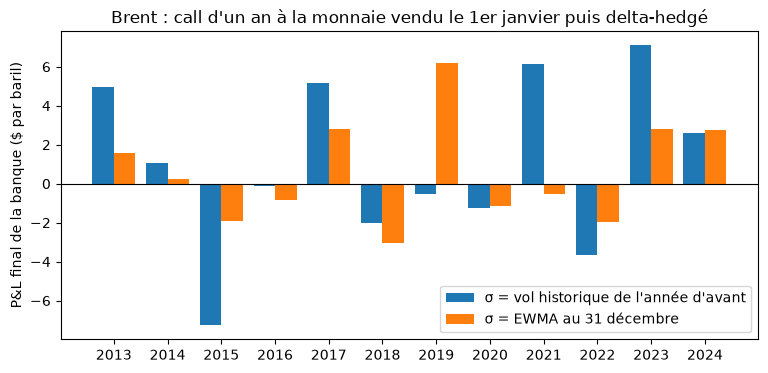

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(years)) # 0, 1, ..., 11: one position per year
ax.bar(x - 0.2, pnl["histo"], width=0.4, label="σ = vol historique de l'année d'avant") # bars shifted left
ax.bar(x + 0.2, pnl["ewma"], width=0.4, label="σ = EWMA au 31 décembre") # and right, side by side
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x, years) # write the years under the bars
ax.set_ylabel("P&L final de la banque ($ par baril)")
ax.set_title("Brent : call d'un an à la monnaie vendu le 1er janvier puis delta-hedgé")
ax.legend()
plt.show()

In [6]:
from math import comb # comb(n, k) = number of ways to choose k items among n

better = np.abs(pnl["ewma"]) < np.abs(pnl["histo"]) # True when EWMA gave the smaller error
k = better.sum()
# if both estimators were equally good, each year would be a coin flip: P(at least k wins out of 12)
p_value = sum(comb(12, j) for j in range(k, 13)) / 2**12
print(f"EWMA meilleur sur {k} années sur 12 ; avec une pièce de monnaie, P(au moins {k}) = {p_value:.0%}")

gain = np.abs(pnl["histo"]) - np.abs(pnl["ewma"]) # > 0: EWMA was better that year
for year, g in zip(years, gain):
    print(f"{year} | gain de l'EWMA {g:+.2f} $")
keep = ~np.isin(years, [2015, 2021, 2023]) # remove the 3 years where EWMA gained the most
print(f"sans 2015, 2021 et 2023 : histo {np.abs(pnl['histo'][keep]).mean():.2f} $ | EWMA {np.abs(pnl['ewma'][keep]).mean():.2f} $")

EWMA meilleur sur 8 années sur 12 ; avec une pièce de monnaie, P(au moins 8) = 19%
2013 | gain de l'EWMA +3.40 $
2014 | gain de l'EWMA +0.82 $
2015 | gain de l'EWMA +5.36 $
2016 | gain de l'EWMA -0.71 $
2017 | gain de l'EWMA +2.31 $
2018 | gain de l'EWMA -1.02 $
2019 | gain de l'EWMA -5.67 $
2020 | gain de l'EWMA +0.07 $
2021 | gain de l'EWMA +5.63 $
2022 | gain de l'EWMA +1.70 $
2023 | gain de l'EWMA +4.30 $
2024 | gain de l'EWMA -0.16 $
sans 2015, 2021 et 2023 : histo 2.37 $ | EWMA 2.29 $


Avec l'EWMA, la banque perd ou gagne en moyenne 2,15 \$ par baril, contre 3,49 \$ avec la vol historique. Mais sur 12 trades, l'EWMA fait mieux 8 fois, ce qu'une pièce de monnaie ferait une fois sur cinq, et l'écart vient surtout de 2015, 2021 et 2023. On ne peut donc pas conclure fermement.

## 3. D'où vient l'erreur ? La « triche »

On refait les 12 trades en donnant à la banque une information qu'elle n'a pas :

| Niveau | Prime | Delta |
|---|---|---|
| réel | σ = EWMA | même σ toute l'année |
| triche | σ = vol réalisée de l'année | même σ toute l'année |
| triche complète | comme la triche | chaque jour, la vol réalisée entre ce jour et l'échéance (`historical_vol(path[i:])`) |

C'est un diagnostic, pas un prix : personne ne connaît la vol future le 1er janvier.

In [7]:
pnl_cheat = [] # level 2: sigma = realized vol of the whole year
for i, year in enumerate(years): # i = 0, 1, ...: position of the year, to read pnl["ewma"][i]
    path = prices[str(year)].to_numpy()
    S0 = path[0]
    K = S0
    payoff_fn = lambda ST: call_payoff(ST, K)
    sigma = historical_vol(path) # realized vol of the year: unknown on January 1st, this is the cheat
    price0 = bs_call(S0, K, T, r, sigma)
    delta_fn = lambda S, time_left: bs_delta(S, K, time_left, r, sigma)
    result = hedge_one_path(path, T, r, price0, delta_fn, payoff_fn)
    pnl_cheat.append(result)
    print(f"{year} | σ réalisé {sigma:4.0%} | P&L réel (EWMA) {pnl['ewma'][i]:+6.2f} "
          f"| P&L triche {result:+6.2f} ({result / price0:+4.0%} de la prime)")
pnl_cheat = np.array(pnl_cheat)

2013 | σ réalisé  17% | P&L réel (EWMA)  +1.57 | P&L triche  +0.69 ( +7% de la prime)
2014 | σ réalisé  21% | P&L réel (EWMA)  +0.22 | P&L triche  +2.27 (+22% de la prime)
2015 | σ réalisé  44% | P&L réel (EWMA)  -1.92 | P&L triche  +0.02 ( +0% de la prime)
2016 | σ réalisé  45% | P&L réel (EWMA)  -0.84 | P&L triche  +0.01 ( +0% de la prime)
2017 | σ réalisé  24% | P&L réel (EWMA)  +2.83 | P&L triche  +0.04 ( +1% de la prime)
2018 | σ réalisé  31% | P&L réel (EWMA)  -3.05 | P&L triche  +0.01 ( +0% de la prime)
2019 | σ réalisé  31% | P&L réel (EWMA)  +6.18 | P&L triche  -0.32 ( -4% de la prime)
2020 | σ réalisé  71% | P&L réel (EWMA)  -1.16 | P&L triche  +2.47 (+13% de la prime)
2021 | σ réalisé  33% | P&L réel (EWMA)  -0.51 | P&L triche  +0.01 ( +0% de la prime)
2022 | σ réalisé  47% | P&L réel (EWMA)  -1.95 | P&L triche  +1.83 (+12% de la prime)
2023 | σ réalisé  32% | P&L réel (EWMA)  +2.80 | P&L triche  +0.03 ( +0% de la prime)
2024 | σ réalisé  27% | P&L réel (EWMA)  +2.78 | P&L t

In [8]:
pnl_full_cheat = [] # level 3: on each day, sigma = realized vol from that day to maturity
for year in years:
    path = prices[str(year)].to_numpy()
    S0 = path[0]
    K = S0
    n_steps = len(path) - 1
    payoff_fn = lambda ST: call_payoff(ST, K)
    # vol from day i to the end of the year; the last 2 days have too few prices left, keep the last value
    sigma_left = [historical_vol(path[i:]) for i in range(n_steps - 1)]
    sigma_left = sigma_left + [sigma_left[-1]] * 2
    price0 = bs_call(S0, K, T, r, historical_vol(path)) # same premium as the cheat
    # hedge_one_path only gives (S, time_left): the day number is i = (T - time_left) * n_steps
    delta_fn = lambda S, time_left: bs_delta(S, K, time_left, r, sigma_left[round((T - time_left) * n_steps)])
    result = hedge_one_path(path, T, r, price0, delta_fn, payoff_fn)
    pnl_full_cheat.append(result)
    print(f"{year} | vol restante : {sigma_left[0]:.0%} le 1er jour, entre {min(sigma_left):.0%} et {max(sigma_left):.0%} "
          f"dans l'année | P&L triche complète {result:+6.2f}")
pnl_full_cheat = np.array(pnl_full_cheat)

print()
print(f"P&L absolu moyen : réel {np.abs(pnl['ewma']).mean():.2f} $ | triche {np.abs(pnl_cheat).mean():.2f} $ "
      f"| triche complète {np.abs(pnl_full_cheat).mean():.2f} $")

2013 | vol restante : 17% le 1er jour, entre 6% et 18% dans l'année | P&L triche complète  +0.43
2014 | vol restante : 21% le 1er jour, entre 11% et 45% dans l'année | P&L triche complète  +0.16
2015 | vol restante : 44% le 1er jour, entre 34% et 65% dans l'année | P&L triche complète  +0.14


2016 | vol restante : 45% le 1er jour, entre 1% et 45% dans l'année | P&L triche complète  -0.01
2017 | vol restante : 24% le 1er jour, entre 7% et 25% dans l'année | P&L triche complète  -0.04


2018 | vol restante : 31% le 1er jour, entre 31% et 90% dans l'année | P&L triche complète  -0.20
2019 | vol restante : 31% le 1er jour, entre 19% et 45% dans l'année | P&L triche complète  -0.24
2020 | vol restante : 71% le 1er jour, entre 4% et 77% dans l'année | P&L triche complète  -0.20
2021 | vol restante : 33% le 1er jour, entre 18% et 52% dans l'année | P&L triche complète  +0.03
2022 | vol restante : 47% le 1er jour, entre 34% et 62% dans l'année | P&L triche complète  +0.34
2023 | vol restante : 32% le 1er jour, entre 1% et 38% dans l'année | P&L triche complète  +0.79
2024 | vol restante : 27% le 1er jour, entre 0% et 32% dans l'année | P&L triche complète  +0.15

P&L absolu moyen : réel 2.15 $ | triche 0.64 $ | triche complète 0.23 $


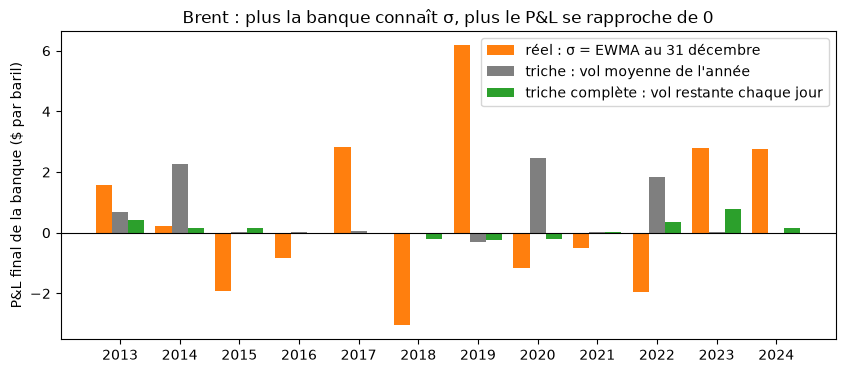

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - 0.27, pnl["ewma"], width=0.27, color="tab:orange", label="réel : σ = EWMA au 31 décembre")
ax.bar(x, pnl_cheat, width=0.27, color="tab:gray", label="triche : vol moyenne de l'année")
ax.bar(x + 0.27, pnl_full_cheat, width=0.27, color="tab:green", label="triche complète : vol restante chaque jour")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x, years)
ax.set_ylabel("P&L final de la banque ($ par baril)")
ax.set_title("Brent : plus la banque connaît σ, plus le P&L se rapproche de 0")
ax.legend()
plt.show()

Le P&L absolu moyen passe de 2,15 \$ (réel) à 0,64 \$ (triche) puis 0,23 \$ (triche complète). Les trois années où la triche reste loin de 0 sont 2014, 2020 et 2022. La cellule suivante compare la vol des jours où le Brent est près du strike (à moins de 15 %) et celle des autres jours.

In [10]:
for year in [2014, 2020, 2022]:
    path = prices[str(year)].to_numpy()
    K = path[0]
    returns = np.diff(np.log(path)) # returns[j]: move from day j to day j+1
    near = np.abs(path[1:] / K - 1) < 0.15 # True when the day ends within 15% of the strike
    vol_near = returns[near].std() * np.sqrt(252)
    vol_far = returns[~near].std() * np.sqrt(252) # ~ flips True <-> False: the other days
    print(f"{year} | prix de {path.min():.0f} à {path.max():.0f} $, strike {K:.0f} $ "
          f"| près : {near.sum():3d} jours, vol {vol_near:.0%} | loin : {(~near).sum():3d} jours, vol {vol_far:.0%} "
          f"| vol de l'année {historical_vol(path):.0%}")

2014 | prix de 57 à 115 $, strike 108 $ | près : 190 jours, vol 14% | loin :  59 jours, vol 33% | vol de l'année 21%
2020 | prix de 19 à 69 $, strike 66 $ | près :  26 jours, vol 26% | loin : 226 jours, vol 75% | vol de l'année 71%
2022 | prix de 76 à 128 $, strike 79 $ | près :  64 jours, vol 35% | loin : 186 jours, vol 50% | vol de l'année 47%


Ces trois années, la vol est basse quand le prix est près du strike (Γ grand) et forte quand il s'en est éloigné (Γ petit). Une vol constante, même juste en moyenne, dose donc mal le delta au bon moment.

## Ce qu'on retient

| Source d'erreur | Coût moyen sur nos 12 trades |
|---|---|
| σ estimé le 1er janvier (la prime) | ≈ 1,5 \$ |
| hypothèse de vol constante (le delta) | ≈ 0,4 \$ |
| ce qui reste (rebalancement quotidien, sauts, vol mesurée sur peu de jours) | ≈ 0,2 \$ |

La méthode de couverture et la formule fonctionnent ; l'erreur vient surtout de l'estimation de σ. Ce sont des ordres de grandeur : 12 trades, un sous-jacent, une maturité, un strike.